In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import random
from matplotlib.colors import ListedColormap
import pandas as pd 

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import os
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv("dt_lab7/fashion-mnist_test.csv")      # <-- pon aquí el nombre de tu archivo
print("Con label:", df.shape)                            # (filas, 785)

df_emnist = df.drop(columns="label")                     # quita la columna de etiquetas
del df                                                   # borra el original, para no usar label sin querer

print("Sin label:", df_emnist.shape)                     # (filas, 784)
df_emnist.head()

Con label: (10000, 785)
Sin label: (10000, 784)


,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,9,8,0,...,103,87,56,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,14,53,99,17,...,0,0,0,0,63,53,31,0,0,0
3,0,0,0,0,0,0,0,0,0,161,...,137,126,140,0,133,224,222,56,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(df_emnist, random_state=42)  
X_test = X_test[:40]
print(X_train.shape, X_test.shape)

(7500, 784) (40, 784)


In [5]:
X_train = X_train.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

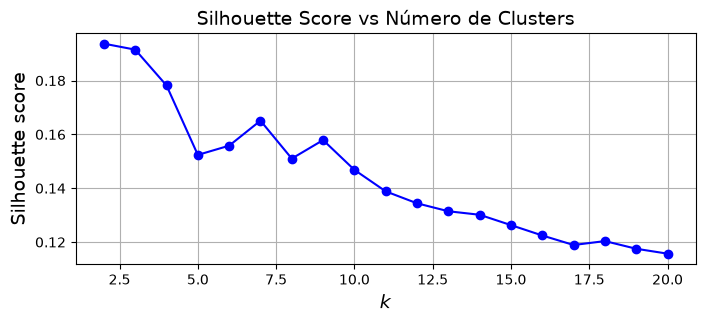

In [6]:
X = X_train.values 
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 10)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

max_k = 20 # no más de los centros generados
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]
# Generar eje x para k de 2 hasta max_k
ks = list(range(2, max_k + 1))

# plt.figure(figsize=(8, 3))
# plt.plot(ks, silhouette_scores, "bo-")
# # plt.plot(range(2, 10), silhouette_scores, "bo-")
# plt.xlabel("$k$", fontsize=14)
# plt.ylabel("Silhouette score", fontsize=14)
# plt.axis([1.8, 8.5, 0.55, 0.7])
# plt.show()

plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

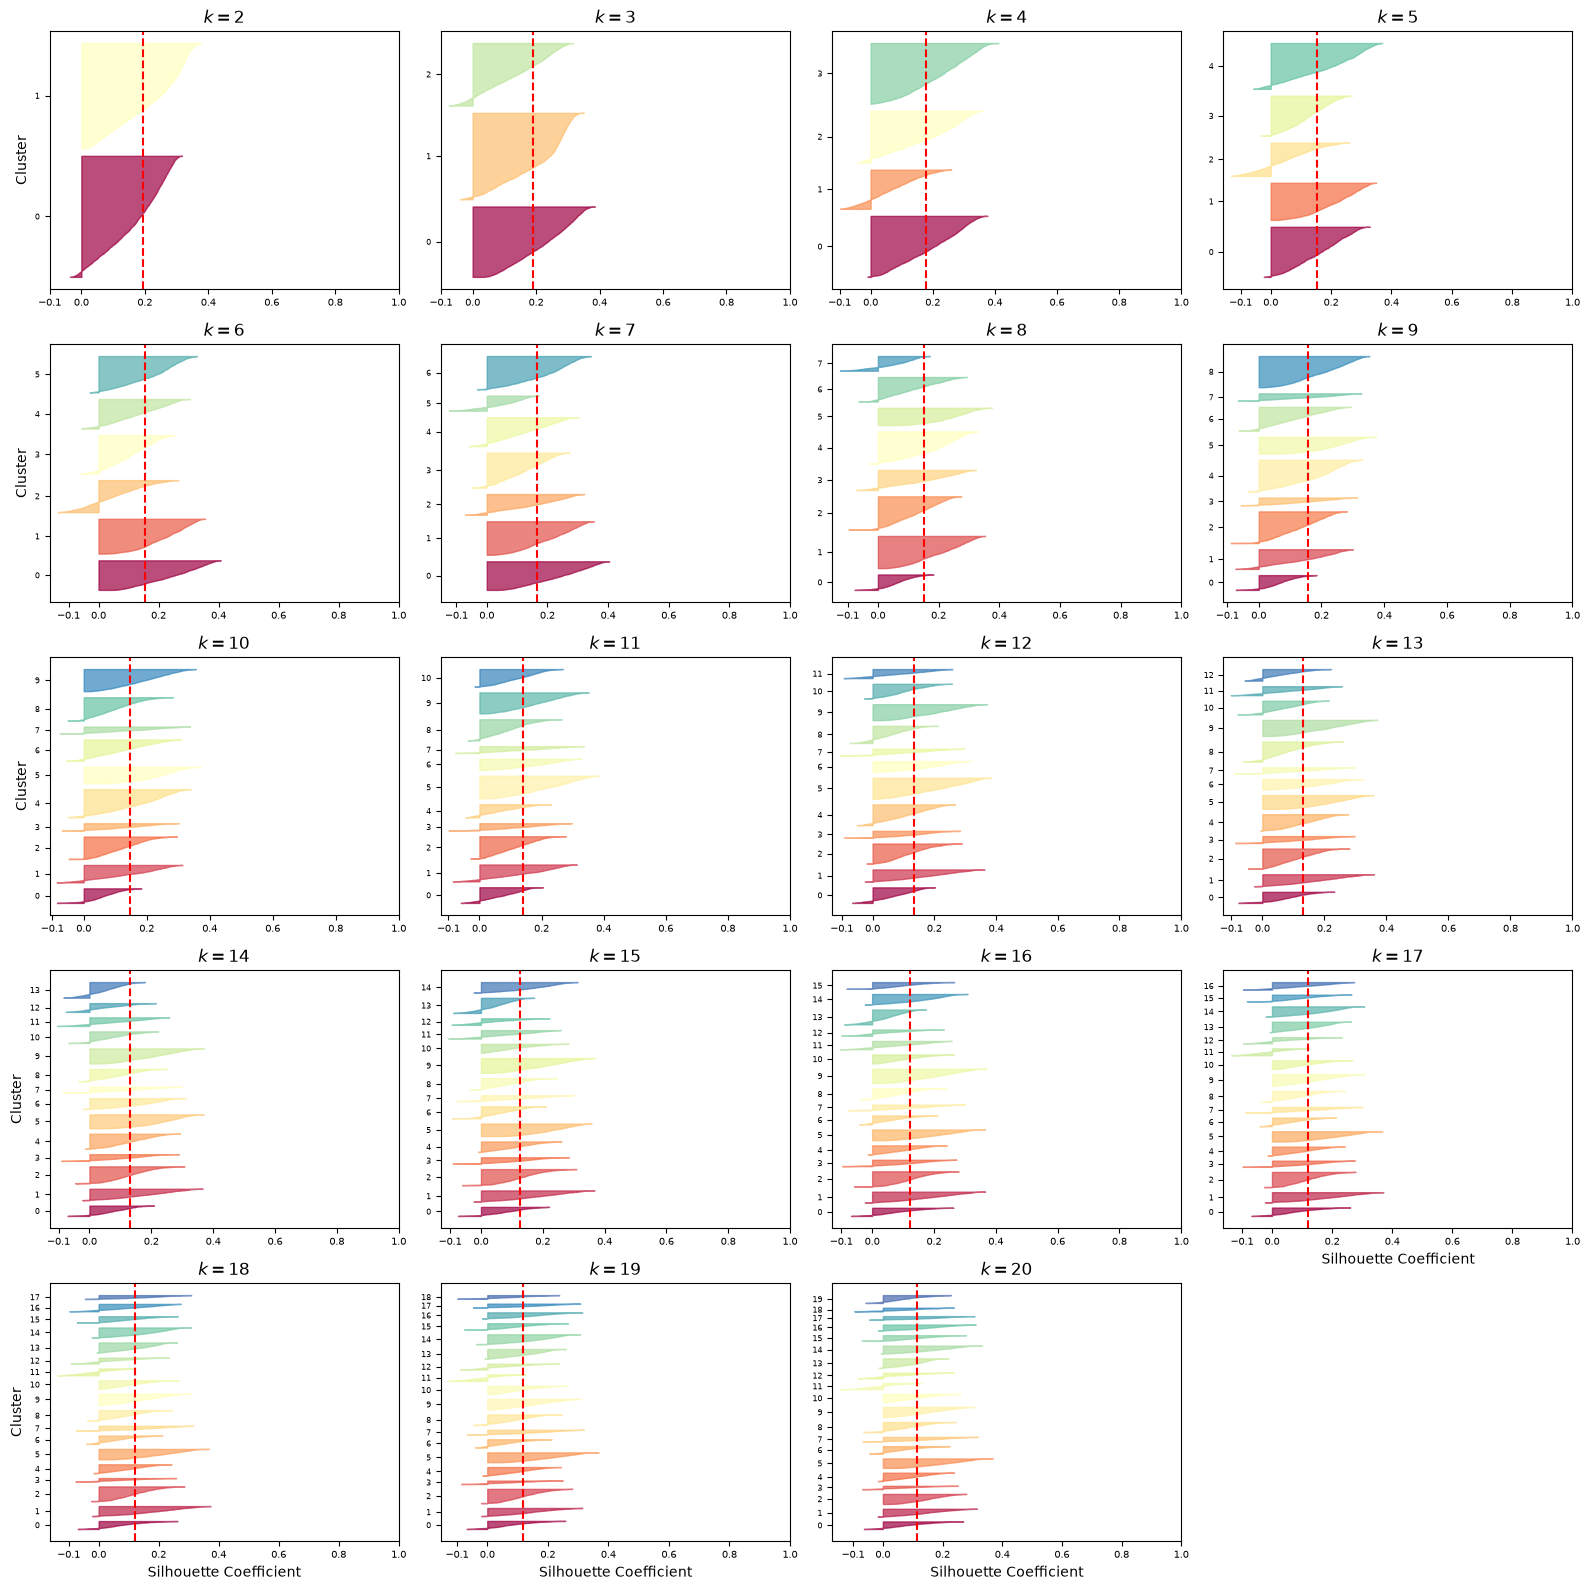

In [7]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

valid_ks = ks                                   # <-- CAMBIO: todos los k (2, 3, ..., max_k)
n_cols = 4                                      # <-- NUEVO: 4 gráficos por fila
n_rows = int(np.ceil(len(valid_ks) / n_cols))   # <-- NUEVO: filas necesarias

plt.figure(figsize=(4 * n_cols, 3.2 * n_rows))  # <-- CAMBIO: el tamaño crece con la cantidad de gráficos

for plot_idx, k in enumerate(valid_ks):
    plt.subplot(n_rows, n_cols, plot_idx + 1)   # <-- CAMBIO: cuadrícula dinámica (antes 2, 2)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    plt.tick_params(axis='y', labelsize=6)                          # <-- NUEVO: números de cluster pequeños para que quepan

    if plot_idx % n_cols == 0:                                      # <-- CAMBIO: etiqueta "Cluster" en la primera columna
        plt.ylabel("Cluster")

    plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])         # <-- CAMBIO: se muestra siempre (antes dependía de k in (3,4,5,6))
    plt.tick_params(axis='x', labelsize=7)
    if plot_idx >= len(valid_ks) - n_cols:                          # <-- CAMBIO: etiqueta x solo en la última fila
        plt.xlabel("Silhouette Coefficient")

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=12)

plt.tight_layout()                                                  # <-- NUEVO: evita que se solapen los títulos
plt.show()

In [8]:
from sklearn.cluster import KMeans

k = 20
kmeans = KMeans(n_clusters=k, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)

print(X_digits_dist.shape)

(7500, 20)


In [9]:
print(X_digits_dist.shape)
print(X_digits_dist)

(7500, 20)
[[ 9.31649506 10.42862522  8.24523467 ...  9.28669829 10.53793846
   7.78952108]
 [13.34236673 13.53483175 13.30756481 ... 10.59236022 11.42623142
  11.14403472]
 [ 6.40447281 12.27849945  8.05402014 ... 12.39391844 13.02473269
   7.83789171]
 ...
 [13.46821968 13.83974873 13.40689389 ... 11.32717557 11.41169841
  11.22893819]
 [13.52936516 12.38904952 12.75182064 ... 10.22857023  7.12777236
  11.84671129]
 [ 9.63243755  8.56916989  7.3829313  ... 10.84201515 12.34858827
   9.43652661]]


In [10]:
idxs = np.argmin(X_digits_dist, axis=0)
X_representative_digits = X_train.values[idxs]

In [11]:
print(X_representative_digits.shape)
print(X_representative_digits)

(20, 784)
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


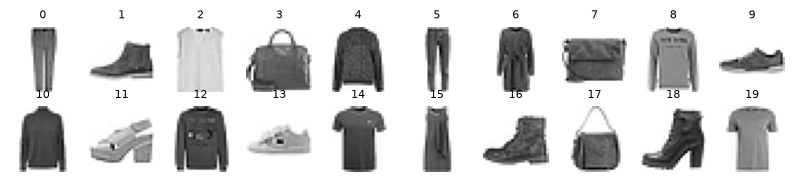

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
for index, X_representative_digit in enumerate(X_representative_digits):
  plt.subplot(5, 10, index+1)
  plt.imshow(X_representative_digit.reshape(28,28), cmap="binary")
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

In [14]:
y_representative_digits = np.array([
    "pantalon", "bota de tobillo", "camiseta", "bolsas", "abrigo", "pantalon", "vestido", "bolsas","jersey", "zapatilla", "jersey", "sandalia", "jersey", "zapatilla", "camiseta", "vestido", "bota de tobillo", "bolsas", "bota de tobillo", "camiseta" 
])
print(len(y_representative_digits))

20


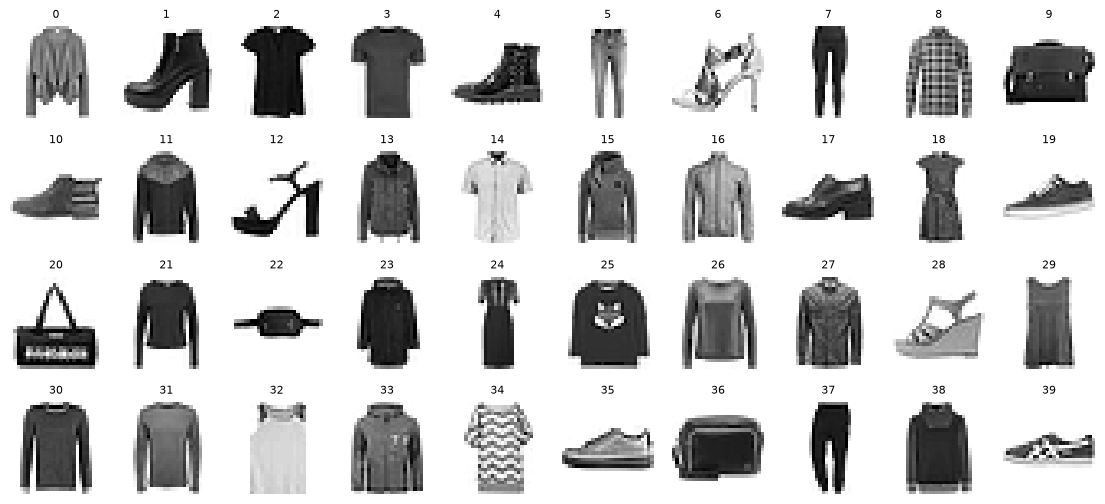

In [15]:
plt.figure(figsize=(14, 16))
for index, img in enumerate(X_test.values):
  plt.subplot(10, 10, index+1)
  plt.imshow(img.reshape(28,28), cmap="binary")
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

In [16]:
y_test = np.array([
    "jersey", "bota de tobillo", "vestido", "camiseta", "bota de tobillo", "pantalon", "sandalia", "pantalon", "camisa", "bolsas", "bota de tobillo", "abrigo", "sandalia", "abrigo", "camisa", "abrigo", "abrigo", "zapatilla", "vestido", "zapatilla", "bolsas", "jersey", "bolsas", "abrigo", "vestido", "jersey", "jersey", "camisa", "sandalia", "vestido", "jersey", "jersey", "camiseta", "abrigo", "jersey", "zapatilla", "bolsas", "pantalon", "abrigo", "zapatilla"
])
print(len(y_test))

40


In [17]:
from sklearn.linear_model import LogisticRegression

log_reg2 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg2.fit(X_representative_digits, y_representative_digits)
log_reg2.score(X_test, y_test)

CPU times: total: 172 ms
Wall time: 182 ms


c:\Users\USUARIO\Desktop\ia_davalos\practicas\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


0.625

In [19]:
y_train_propagated = np.empty(len(X_train), dtype=object)    # <-- CAMBIO: admite texto
for i in range(k):
  y_train_propagated[kmeans.labels_==i] = y_representative_digits[i]

In [20]:
log_reg3 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg3.fit(X_train[:1000], y_train_propagated[:1000])
log_reg3.score(X_test, y_test)

CPU times: total: 36.8 s
Wall time: 2.73 s


0.625

In [21]:
for digito in np.unique(y_representative_digits):
    grupos = np.where(y_representative_digits == digito)[0]
    print(f"Dígito {digito}: grupos {grupos}")

Dígito abrigo: grupos [4]
Dígito bolsas: grupos [ 3  7 17]
Dígito bota de tobillo: grupos [ 1 16 18]
Dígito camiseta: grupos [ 2 14 19]
Dígito jersey: grupos [ 8 10 12]
Dígito pantalon: grupos [0 5]
Dígito sandalia: grupos [11]
Dígito vestido: grupos [ 6 15]
Dígito zapatilla: grupos [ 9 13]


In [22]:
pred2 = log_reg2.predict(X_test)
pred3 = log_reg3.predict(X_test)

print("Imágenes donde predicen distinto:", (pred2 != pred3).sum(), "de", len(y_test))
print("Aciertos log_reg2:", (pred2 == y_test).sum(), "| log_reg3:", (pred3 == y_test).sum())

print("Etiquetas distintas en las 1000 de entrenamiento:", np.unique(y_train_propagated[:1000], return_counts=True))
print("Etiquetas distintas en las representativas:", np.unique(y_representative_digits, return_counts=True))

Imágenes donde predicen distinto: 5 de 40
Aciertos log_reg2: 25 | log_reg3: 25
Etiquetas distintas en las 1000 de entrenamiento: (array([np.str_('abrigo'), np.str_('bolsas'), np.str_('bota de tobillo'),
       np.str_('camiseta'), np.str_('jersey'), np.str_('pantalon'),
       np.str_('sandalia'), np.str_('vestido'), np.str_('zapatilla')],
      dtype=object), array([ 61,  75, 128, 170, 174, 101,  43,  95, 153]))
Etiquetas distintas en las representativas: (array(['abrigo', 'bolsas', 'bota de tobillo', 'camiseta', 'jersey',
       'pantalon', 'sandalia', 'vestido', 'zapatilla'], dtype='<U15'), array([1, 3, 3, 3, 3, 2, 1, 2, 2]))


c:\Users\USUARIO\Desktop\ia_davalos\practicas\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


aprendizaje activo

In [23]:
probas = log_reg3.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
sorted_ixs = np.argsort(labels)
labels[sorted_ixs[:10]]

array([0.6868476 , 0.68968907, 0.69145035, 0.70699704, 0.71757714,
       0.72435237, 0.72836337, 0.73793818, 0.74793298, 0.75337441])

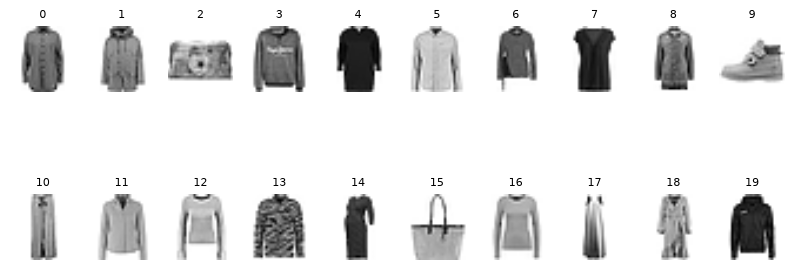

In [25]:
n_consulta = 20                                                  # <-- NUEVO: cuántas imágenes vas a etiquetar por ronda

X_lowest = X_train.values[:1000][sorted_ixs[:n_consulta]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(int(np.ceil(n_consulta / 10)), 10, index + 1)    # <-- CAMBIO: filas calculadas (antes k // 10)
    plt.imshow(img.reshape(28, 28), cmap="binary", interpolation="bilinear")
    plt.title(index, fontsize=8)                                 # <-- NUEVO: número de cada imagen
    plt.axis('off')
plt.show()

In [26]:
y_lowest = np.array([
    "abrigo", "abrigo", "bolsas", "jersey", "vestido", "camisa", "jersey", "camiseta", "abrigo", "bota de tobillo", "pantalón", "abrigo", "jersey", "abrigo", "vestido", "bolsas", "jersey", "vestido", "abrigo", "abrigo"
])
assert len(y_lowest) == n_consulta

In [27]:
print(y_train_propagated[:1000][sorted_ixs[:n_consulta]])

[np.str_('vestido') np.str_('camiseta') np.str_('bota de tobillo')
 np.str_('abrigo') np.str_('camiseta') np.str_('camiseta')
 np.str_('jersey') np.str_('camiseta') np.str_('vestido')
 np.str_('sandalia') np.str_('pantalon') np.str_('jersey')
 np.str_('camiseta') np.str_('abrigo') np.str_('vestido')
 np.str_('camiseta') np.str_('jersey') np.str_('pantalon')
 np.str_('pantalon') np.str_('jersey')]


In [28]:
y_train2 = y_train_propagated[:1000].copy()
y_train2[sorted_ixs[:n_consulta]] = y_lowest

In [29]:
log_reg5 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)    # sin multi_class
%time log_reg5.fit(X_train[:1000], y_train2)
log_reg5.score(X_test, y_test)

CPU times: total: 32.5 s
Wall time: 2.23 s


0.65

ronda de correccion numero 2

In [30]:
ya_corregidas = np.zeros(1000, dtype=bool)
ya_corregidas[sorted_ixs[:n_consulta]] = True            # marca las de la ronda 1

probas = log_reg5.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
labels[ya_corregidas] = 2                                # confianza imposible: quedan al final del orden
sorted_ixs = np.argsort(labels)

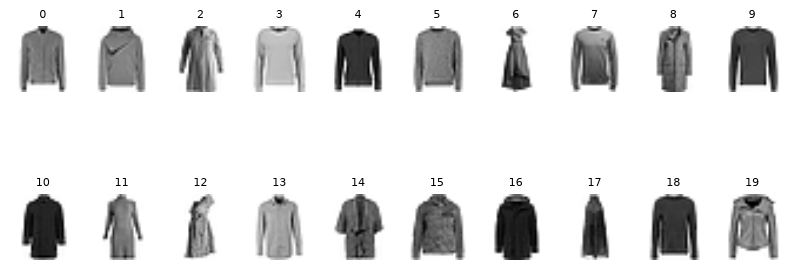

In [31]:
n_consulta = 20                                                  # <-- NUEVO: cuántas imágenes vas a etiquetar por ronda

X_lowest = X_train.values[:1000][sorted_ixs[:n_consulta]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(int(np.ceil(n_consulta / 10)), 10, index + 1)    # <-- CAMBIO: filas calculadas (antes k // 10)
    plt.imshow(img.reshape(28, 28), cmap="binary", interpolation="bilinear")
    plt.title(index, fontsize=8)                                 # <-- NUEVO: número de cada imagen
    plt.axis('off')
plt.show()

In [32]:
y_lowest = np.array([
    "abrigo", "abrigo", "abrigo", "jersey", "abrigo", "jersey", "vestido", "jersey", "abrigo", "jersey", "abrigo", "vestido", "abrigo", "camisa", "abrigo", "abrigo", "abrigo", "vestido", "jersey", "abrigo"
])
assert len(y_lowest) == n_consulta

In [33]:
y_train3 = y_train2.copy()                               # parte de lo ya corregido
y_train3[sorted_ixs[:n_consulta]] = y_lowest             # y_lowest = tus nuevas etiquetas
log_reg6 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
log_reg6.fit(X_train[:1000], y_train3)
log_reg6.score(X_test, y_test)

0.65